In [159]:
# %pip install yfinance pandas numpy matplotlib seaborn scipy statsmodels scikit-learn ipykernel requests beautifulsoup4 lxml python-dateutil

In [160]:

# Import libraries
import yfinance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, bds
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
import yfinance as yf  # my code uses the 'yf' alias
from sklearn.linear_model import RidgeCV, LassoCV, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
# NOTE: Should not download the getFamaFrench_factors.py file off the internet,
# Martin says that you should only use the file from the course.

In [161]:
TICKER = "MRK"
START = "2010-01-01"

In [162]:
# FamaFrench Factors must be manually loaded. getFamaFrench_factors.py must be uploaded everytime you start runtime.
from econ3206 import getFamaFrench_factors as gff

In [163]:
# MRK is the dicker for assigned company.
mrk = yfinance.Ticker('MRK')

In [164]:
# Specify the last 2 years.
ts_daily = mrk.history(period = '2y', interval = '1d')
ts_hourly = mrk.history(period = '2y', interval = '1h')

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

In [165]:
print("Daily observations:", len(ts_daily))
print("Hourly observations:", len(ts_hourly))

print("Daily data starts:", ts_daily.index.min())
print("Daily data ends:", ts_daily.index.max())

print("Hourly data starts:", ts_hourly.index.min())
print("Hourly data ends:", ts_hourly.index.max())

Daily observations: 501
Hourly observations: 3477
Daily data starts: 2024-10-31 00:00:00-04:00
Daily data ends: 2026-10-30 00:00:00-04:00
Hourly data starts: 2024-10-31 09:30:00-04:00
Hourly data ends: 2026-10-30 15:30:00-04:00


In [166]:
# Construct new dataframe for log return
# Must use 'Close' prices.
# Drop any NaN - includes 0s?
log_return_daily = np.log(ts_daily['Close'] / (ts_daily['Close'].shift(1))).dropna()
log_return_hourly = np.log(ts_hourly['Close'] / (ts_hourly['Close'].shift(1))).dropna()

# Question 2

Text(0, 0.5, 'Close (%)')

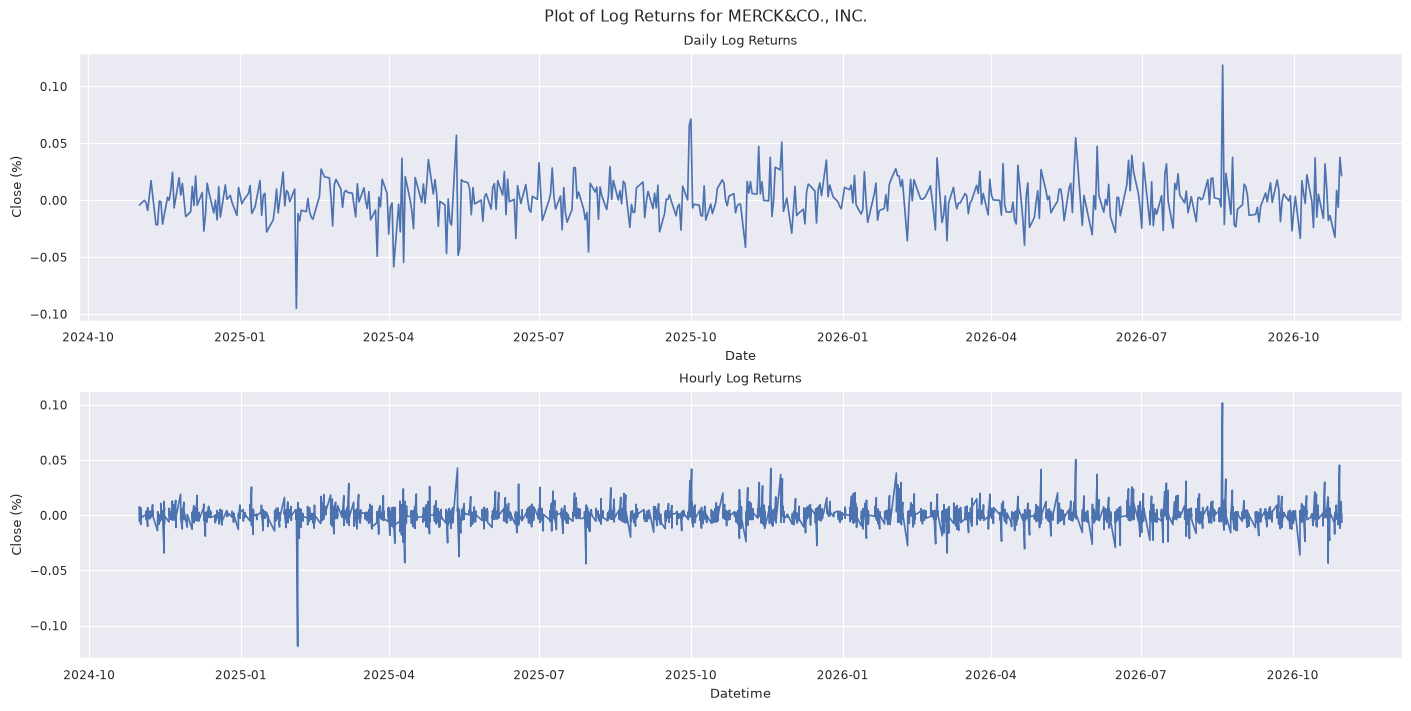

In [167]:
# Set theme & style(cosmetric)
sns.set_theme('paper')
sns.set_style('darkgrid')
# Plot log-returns over time.
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (14, 7), layout = 'constrained')

sns.lineplot(data = log_return_daily, ax = axes[0])
sns.lineplot(data = log_return_hourly, ax = axes[1])

fig.suptitle("Plot of Log Returns for MERCK&CO., INC.")
axes[0].set_title("Daily Log Returns")
axes[1].set_title("Hourly Log Returns")
axes[0].set_ylabel("Close (%)")
axes[1].set_ylabel("Close (%)")

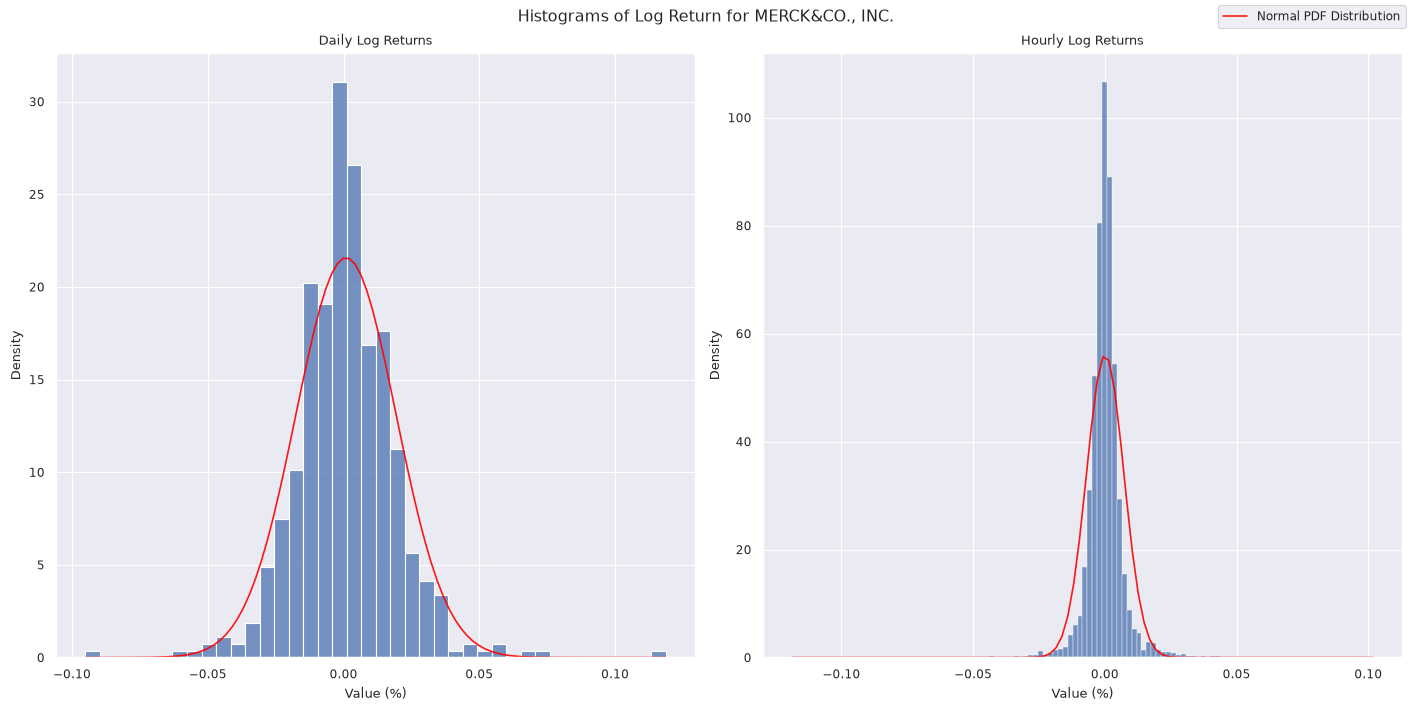

In [168]:
# Set theme & style(cosmetric)
sns.set_theme('paper')
sns.set_style('darkgrid')
# Plot log_return over normal distribution.
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14, 7), layout = 'constrained')

sns.histplot(x = log_return_daily, stat = 'density', ax = axes[0])
sns.histplot(x = log_return_hourly, stat = 'density', ax = axes[1])

# Fit log returns to normal distribution.
mu_daily, std_daily = stats.norm.fit(log_return_daily)
mu_hourly, std_hourly = stats.norm.fit(log_return_hourly)

# Generate x values over normal PDF.
x_daily = np.linspace(min(log_return_daily), max(log_return_daily), 100)
x_hourly = np.linspace(min(log_return_hourly), max(log_return_hourly), 100)

pdf_daily = stats.norm.pdf(x_daily, mu_daily, std_daily)
pdf_hourly = stats.norm.pdf(x_hourly, mu_hourly, std_hourly)

sns.lineplot(x = x_daily, y = pdf_daily, ax = axes[0], alpha = 0.9, color = 'red', label = 'Normal PDF Distribution', legend = False)
sns.lineplot(x = x_hourly, y = pdf_hourly, ax = axes[1], alpha = 0.9, color = 'red', legend = False)

handles, labels = axes[0].get_legend_handles_labels()

axes[0].set_title("Daily Log Returns")
axes[1].set_title("Hourly Log Returns")
axes[0].set_xlabel("Value (%)")
axes[1].set_xlabel("Value (%)")
fig.suptitle("Histograms of Log Return for MERCK&CO., INC.")
fig.legend(handles, labels, loc="upper right")

Text(0.5, 1.0, 'Plot of Hourly Log Returns')

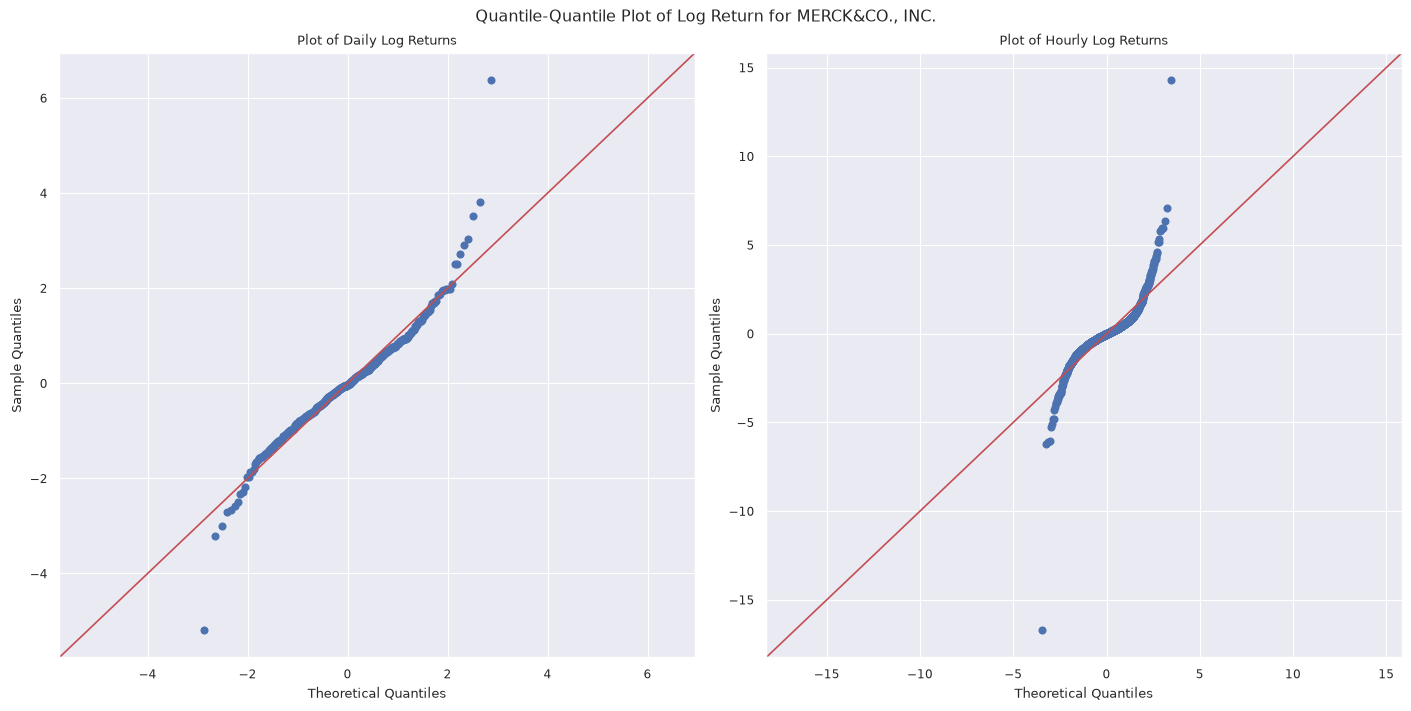

In [169]:
# Plot QQ
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14, 7), layout = 'constrained')

# Set Seaborn Cosmetric
sns.set_theme('paper')
sns.set_style('darkgrid')

# Use statsmodel's QQPlot function
sm.qqplot(log_return_daily, dist = stats.norm, line = '45', fit = 'True', ax = axes[0])
sm.qqplot(log_return_hourly, dist = stats.norm, line = '45', fit = 'True', ax = axes[1])

fig.suptitle("Quantile-Quantile Plot of Log Return for MERCK&CO., INC.")
axes[0].set_title("Plot of Daily Log Returns")
axes[1].set_title("Plot of Hourly Log Returns")

In [170]:
# Display descriptive stats for daily and hourly series.
ts_daily['Close'].agg(['mean', 'std', 'skew', 'kurtosis'])

mean        101.687027
std          22.470604
skew          0.642863
kurtosis     -0.647296
Name: Close, dtype: float64

In [171]:
ts_hourly['Close'].agg(['mean', 'std', 'skew', 'kurtosis'])

mean        104.520673
std          21.379379
skew          0.594421
kurtosis     -0.638369
Name: Close, dtype: float64

In [172]:
# Descriptive statistics for hourly and daily log returns

ts_descriptive_stats = pd.concat(
    [log_return_hourly, log_return_daily],
    axis=1,
    keys=['Hourly Log Returns', 'Daily Log Returns']
)

ts_descriptive_stats.agg(
    ['mean', 'std', 'skew', 'kurtosis']
).T

/tmp/ipykernel_67202/1648866777.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  ts_descriptive_stats = pd.concat(


,mean,std,skew,kurtosis
Hourly Log Returns,0.000110,0.007113,-0.098455,40.700169
Daily Log Returns,0.000889,0.018512,0.371692,5.125843


# Question 3

## Part A

In [173]:
# Load max period for MRK
ts_daily_max = mrk.history(period = 'max', interval = '1d')

# Simple Returns, 'Close' is automatically adjusted in recent versions.
mrk_return_daily = ts_daily_max['Close'].pct_change().dropna()

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

In [174]:
# S&P500 - ticker: ^GSPC
snp500 = yfinance.Ticker('^GSPC')
# T-Bill
t_bill = yfinance.Ticker('^IRX')

In [175]:
# 3 month / 13 week
# Specify max period to ensure that calculations are accurately.
snp500_daily = snp500.history(period = 'max', interval = '1d')
t_bill_rr = t_bill.history(period = 'max', interval = '1d')

# Strip timezone so it aligns with tz-naive.
snp500_daily.index = pd.to_datetime(snp500_daily.index).tz_localize(None).normalize()
t_bill_rr.index = pd.to_datetime(t_bill_rr.index).tz_localize(None).normalize()

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=

In [176]:
# pct_change calculates simple returns
snp500_daily_return = snp500_daily['Close'].pct_change().dropna()
t_bill_rr = t_bill_rr['Close']

In [177]:
# Load Fama-French Factors
# NOTE: You must upload getFamaFrench_factors everytime you start runtime (files get auto deleted everytime runtime is terminated).
ff3_data = gff.famaFrench3Factor(frequency = 'd')

In [178]:
# Set Index to Date
ff3_data.set_index('Date', inplace = True)

/tmp/ipykernel_67202/2730558795.py:2: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ff3_data.set_index('Date', inplace = True)


In [179]:
ff3_data

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07-01,0.0009,-0.0023,-0.0028,0.0001
1926-07-02,0.0045,-0.0034,-0.0003,0.0001
1926-07-06,0.0017,0.0029,-0.0038,0.0001
1926-07-07,0.0009,-0.0062,0.0003,0.0001
1926-07-08,0.0022,-0.0038,0.0018,0.0001
...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001
2026-09-24,-0.0004,-0.0019,0.0023,0.0001
2026-09-25,0.0043,-0.0038,0.0041,0.0001


In [ ]:
# Check which has timezone signatures.
# This is tz-naive
ff3_data.index.tz
# This is tz-aware
snp500_daily_return.index.tz

In [201]:
# Merge S&P500 Simple Returns, T-Bill and FF3 data.
snp500_daily_return.name = 'SNP500_ret'
t_bill_rr.name = 'T-Bill_rr'

ff3_new = pd.concat([ff3_data, snp500_daily_return, t_bill_rr], axis = 1, join = 'inner')

In [202]:
ff3_new

,Mkt-RF,SMB,HML,RF,SNP500_ret,T-Bill_rr
Date,,,,,,
1960-01-04,-0.0003,0.0060,0.0067,0.0002,0.000334,4.520
1960-01-05,0.0078,-0.0038,0.0052,0.0002,0.008012,4.550
1960-01-06,-0.0047,0.0013,0.0036,0.0002,-0.004305,4.680
1960-01-07,-0.0065,0.0035,0.0011,0.0002,-0.007318,4.630
1960-01-08,-0.0033,0.0019,0.0007,0.0002,-0.003183,4.590
...,...,...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001,-0.007548,4.028
2026-09-24,-0.0004,-0.0019,0.0023,0.0001,-0.000247,4.068
2026-09-25,0.0043,-0.0038,0.0041,0.0001,0.005099,4.070


In [183]:
# Calculate Excess Returns for snp500.
# Trading days depend on 250 - 253 trading days.
# PS Edmund - 'I will use 252 trading days.
SNP500_ret_ex = ff3_new['SNP500_ret'] - ff3_new['RF']

Text(0, 0.5, 'S&P 500 Excess Return (decimal)')

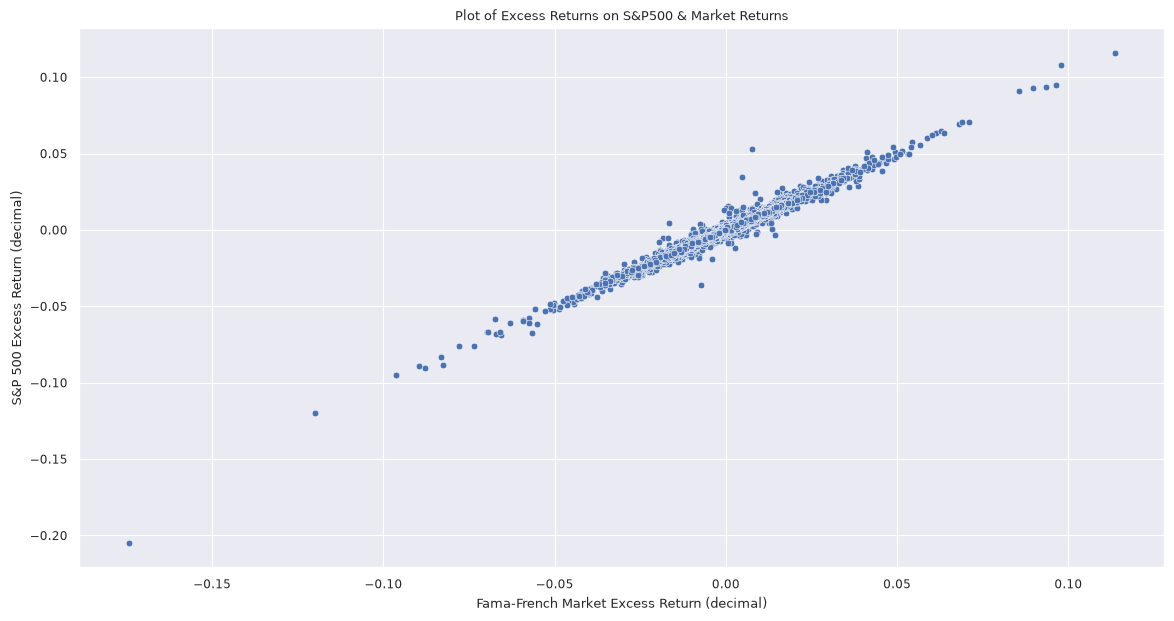

In [184]:
# Plot Excess Returns against
fig, ax = plt.subplots(figsize = (14, 7))

sns.scatterplot(y = SNP500_ret_ex, x = ff3_new['Mkt-RF'], ax = ax)
ax.set_title("Plot of Excess Returns on S&P500 & Market Returns")
ax.set_xlabel("Fama-French Market Excess Return (decimal)")
ax.set_ylabel("S&P 500 Excess Return (decimal)")

## Part B


In [ ]:
# Convert annual T-bill yield to a daily rate using compounding
annual_rate = ff3_new['T-Bill_rr'] / 100

# Use 252 trading days
ff3_new['T-Bill_rr'] = (1 + annual_rate) ** (1 / 252) - 1

# Compare daily T-bill rate with Fama-French RF
ff3_new[['T-Bill_rr', 'RF']].head()

,T-Bill_rr,RF
Date,,
1960-01-04,0.000175,0.0002
1960-01-05,0.000177,0.0002
1960-01-06,0.000182,0.0002
1960-01-07,0.000180,0.0002
1960-01-08,0.000178,0.0002


Text(0, 0.5, 'Risk-Free Rate')

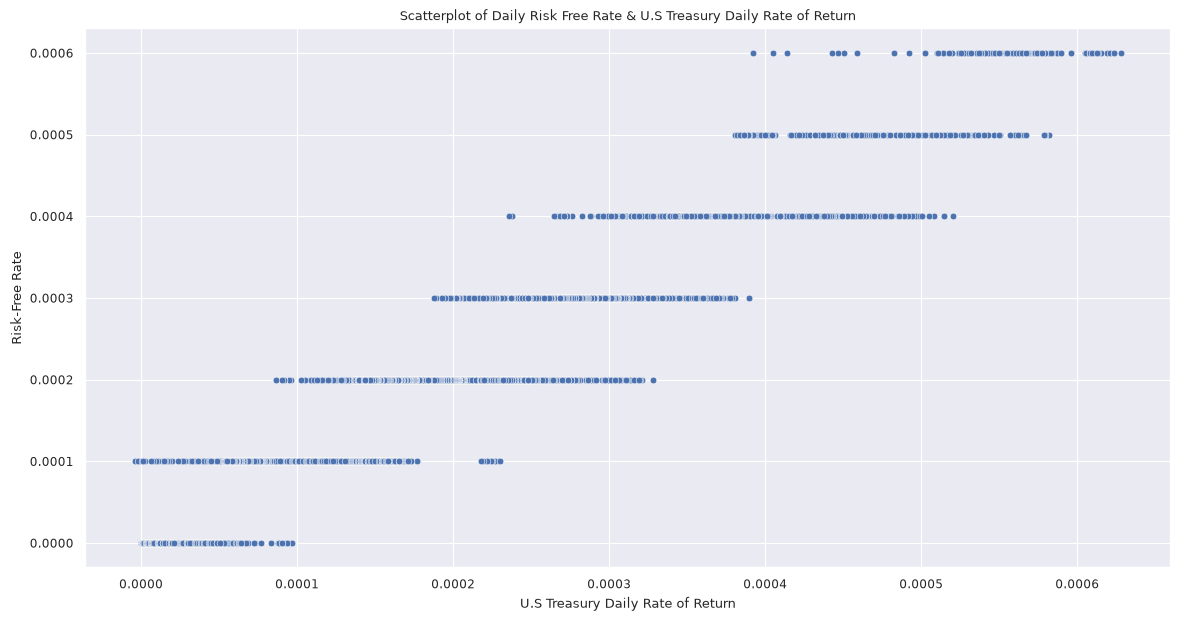

In [186]:
# Plot Scatterplot
fig, ax = plt.subplots(figsize = (14, 7))

sns.scatterplot(data = ff3_new, x = 'T-Bill_rr', y = 'RF', ax = ax)

ax.set_title("Scatterplot of Daily Risk Free Rate & U.S Treasury Daily Rate of Return")
ax.set_xlabel("U.S Treasury Daily Rate of Return")
ax.set_ylabel("Risk-Free Rate")

# Question 4 - CAPM

## Part A

Use HAC var-covar estimate.

In [187]:
# Fetch existing ff3 data.
ff3_mrk = ff3_new.copy()
# Strip tz timzone signatures to align with tz naive.
mrk_return_daily.name = 'MRK_rr'
mrk_return_daily.index = pd.to_datetime(mrk_return_daily.index).tz_localize(None).normalize()
# MRK simple returns daily for max period.
# Match MRK with FamaFrench 3 Data.
ff3_mrk = ff3_mrk.merge(mrk_return_daily, on = 'Date')

In [203]:
ff3_mrk

,Mkt-RF,SMB,HML,RF,SNP500_ret,T-Bill_rr,MRK_rr
Date,,,,,,,
1962-01-03,0.0024,0.0022,0.0096,0.0001,0.002396,0.000107,-0.041900
1962-01-04,-0.0084,0.0001,0.0066,0.0001,-0.006889,0.000107,-0.010203
1962-01-05,-0.0134,0.0007,0.0032,0.0001,-0.013873,0.000107,-0.033874
1962-01-08,-0.0075,0.0022,0.0032,0.0001,-0.007752,0.000109,0.003048
1962-01-09,0.0002,-0.0012,0.0034,0.0001,0.000434,0.000109,0.004561
...,...,...,...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001,-0.007548,0.000157,-0.018753
2026-09-24,-0.0004,-0.0019,0.0023,0.0001,-0.000247,0.000158,-0.000675
2026-09-25,0.0043,-0.0038,0.0041,0.0001,0.005099,0.000158,0.005406


OLS Regression,  $${E[R_{it}] - R_{ft} = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + \epsilon_{it}}$$ $${y = \alpha_{i} + \beta_{i}{X_1} + \epsilon_i}$$

In [204]:
# Compute Excess
y = ff3_mrk['MRK_rr'] - ff3_mrk['RF']
# Market Returns
X1 = ff3_mrk['Mkt-RF']

# Add Col to Intercept.
X1 = sm.add_constant(X1)

# Fit CAPM model.
capm_model = sm.OLS(y, X1).fit(cov_type = 'HAC', cov_kwds = {"maxlags": 5})

# Print Summary Results
print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.244
Method:                 Least Squares   F-statistic:                     1997.
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        19:31:07   Log-Likelihood:                 46485.
No. Observations:               16172   AIC:                        -9.297e+04
Df Residuals:                   16170   BIC:                        -9.295e+04
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.000      1.897      0.0

## Part B

In [ ]:
# Extract values from part (a)
alpha_male, beta = capm_model.params['const'], capm_model.params['Mkt-RF']

This is expressed as $${E[R_A] = \beta_{A}E[R_m] + (1-\beta_{A})E[R_f]}$$

In [215]:
replic_ret_mkt = beta * ff3_mrk['SNP500_ret'] + (1 - beta) * ff3_mrk['T-Bill_rr']

In [213]:
replic_ret_mkt

Date
1962-01-03    0.001851
1962-01-04   -0.005224
1962-01-05   -0.010546
1962-01-08   -0.005881
1962-01-09    0.000357
                ...   
2026-09-23   -0.005715
2026-09-24   -0.000150
2026-09-25    0.003923
2026-09-28   -0.005839
2026-09-29   -0.001237
Length: 16172, dtype: float64

## Part C

Recall CAPM model: 
$${E[R_{it}] - R_{ft} = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + \epsilon_{it}}$$
Rearrange, 
$${E[R_{it}] = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + R_{ft} + \epsilon_{it}}$$

# Question 5 - APT

In [191]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
# Load famaFrench 5 factors.
ff5_data = gff.famaFrench5Factor(frequency = 'd')
ff5_data.set_index('Date')
ff5_data = ff5_data.merge(mrk_return_daily, on = 'Date')

ff5_factors = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
y_full = ff5_data["MRK_rr"]
X5 = sm.add_constant(ff5_data[ff5_factors])

# Classical OLS (used for AIC/BIC and diagnostics) and HAC version (used for inference)
ff5_ols = sm.OLS(y_full, X5).fit()
ff5_hac = sm.OLS(y_full, X5).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ff5_hac.summary())

# Joint F-test: are all five factor loadings zero? (HAC-robust)
R = np.hstack([np.zeros((5, 1)), np.eye(5)])
print("\nJoint test that all factor loadings = 0:")
print(ff5_hac.f_test(R))

# Test of alpha (in % per day)
print(f"\nAlpha = {ff5_hac.params['const']:.4f}% per day, "
      f"t = {ff5_hac.tvalues['const']:.2f}, p = {ff5_hac.pvalues['const']:.4f}")

# Residual diagnostics
bp_stat, bp_p, _, _ = het_breuschpagan(ff5_ols.resid, X5)
print(f"\nDurbin-Watson: {durbin_watson(ff5_ols.resid):.3f}")
print(f"Breusch-Pagan p-value (heteroskedasticity): {bp_p:.4f}")
print(f"Jarque-Bera p-value (normality): {stats.jarque_bera(ff5_ols.resid)[1]:.4f}")

                            OLS Regression Results                            
Dep. Variable:                 MRK_rr   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     563.3
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:43:10   Log-Likelihood:                 46249.
No. Observations:               15917   AIC:                        -9.249e+04
Df Residuals:                   15911   BIC:                        -9.244e+04
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      2.761      0.0

## 5 C


In [192]:
# Load famaFrench 5 factors.
ff5_data = gff.famaFrench5Factor(frequency = 'd')
ff5_data.set_index('Date')
ff5_data = ff5_data.merge(mrk_return_daily, on = 'Date')
# Load Momentum Factors.
mom_data = gff.momentumFactor(frequency = 'd')
mom_data = mom_data.set_index('Date')
ff6_data = ff5_data.merge(mom_data, on = 'Date')

ff6_factors = ff5_factors + ["MOM"]
X6 = sm.add_constant(ff6_data[ff6_factors])

ff6_ols = sm.OLS(y_full, X6).fit()
ff6_hac = sm.OLS(y_full, X6).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ff6_hac.summary())

print(f"\nMomentum loading = {ff6_hac.params['MOM']:.4f}, "
      f"t = {ff6_hac.tvalues['MOM']:.2f}, p = {ff6_hac.pvalues['MOM']:.4f}")

# Side-by-side comparison of FF5 vs FF5 + Momentum
comparison = pd.DataFrame({
    "R2": [ff5_ols.rsquared, ff6_ols.rsquared],
    "Adj R2": [ff5_ols.rsquared_adj, ff6_ols.rsquared_adj],
    "AIC": [ff5_ols.aic, ff6_ols.aic],
    "BIC": [ff5_ols.bic, ff6_ols.bic],
}, index=["FF5", "FF5 + Momentum"])
print("\n", comparison.round(4))

# Nested F-test: does adding Mom significantly improve the fit?
f_stat, f_p, df_diff = ff6_ols.compare_f_test(ff5_ols)
print(f"\nNested F-test (FF5 vs FF5 + Mom): F = {f_stat:.3f}, p = {f_p:.4f}")

                            OLS Regression Results                            
Dep. Variable:                 MRK_rr   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     474.5
Date:                Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:43:12   Log-Likelihood:                 46250.
No. Observations:               15917   AIC:                        -9.249e+04
Df Residuals:                   15910   BIC:                        -9.243e+04
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      2.824      0.0

## 5 E

## Loading the required Data

In [193]:
def load_prices(tickers, start):
    px = yf.download(tickers, start=start, auto_adjust=True, progress=False)["Close"]
    return px

def load_ff(start):
    ff5 = web.DataReader("F-F_Research_Data_5_Factors_2x3_daily", "famafrench", start=start)[0]
    mom = web.DataReader("F-F_Momentum_Factor_daily", "famafrench", start=start)[0]
    mom.columns = [c.strip() for c in mom.columns]
    ff = ff5.join(mom, how="inner")
    ff.columns = [c.strip() for c in ff.columns]
    # Fama-French returns a PeriodIndex; convert to normal timestamps so it matches Yahoo dates
    if isinstance(ff.index, pd.PeriodIndex):
        ff.index = ff.index.to_timestamp()
    ff.index = pd.to_datetime(ff.index).tz_localize(None).normalize()
    return ff  # already in percent

px = load_prices([TICKER, "CL=F"], START)
px.index = pd.to_datetime(px.index).tz_localize(None).normalize()   # remove timezone if present
rets = px.pct_change(fill_method=None).dropna() * 100              # simple returns in %
ff = load_ff(START)

print("returns:", rets.shape, rets.index.min(), "->", rets.index.max())
print("ff:     ", ff.shape, ff.index.min(), "->", ff.index.max())

df = rets.join(ff, how="inner").dropna()
print("merged: ", df.shape)

df["ExcessRet"] = df[TICKER] - df["RF"]
df["Oil"] = df["CL=F"]                          # oil return as an extra factor

factors = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "Oil"]
y = df["ExcessRet"]
X = df[factors]
print(df[["ExcessRet"] + factors].describe().round(3))
print("\nCorrelation matrix of factors (multicollinearity check):")
print(X.corr().round(2))

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=

NameError: name 'web' is not defined

## Split the dataset into a Train and Test Set

In [ ]:
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Standardise using TRAIN statistics only (penalised models need comparable scales)
scaler = StandardScaler().fit(X_train)
Xs_train = scaler.transform(X_train)
Xs_test = scaler.transform(X_test)

## OLS (baseline, with Newey-West HAC standard errors)

In [ ]:
X_train_c = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_c).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ols.summary())

ols_pred = ols.predict(sm.add_constant(X_test, has_constant="add"))

# VIFs for multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series(
    [variance_inflation_factor(X_train_c.values, i + 1) for i in range(len(factors))],
    index=factors, name="VIF")
print("\nVariance inflation factors:\n", vif.round(2))

##  Ridge Regression with L2 Penalty

In [ ]:
tscv = TimeSeriesSplit(n_splits=5)

alphas_ridge = np.logspace(-3, 4, 100)
ridge = RidgeCV(alphas=alphas_ridge, cv=tscv).fit(Xs_train, y_train)
ridge_pred = ridge.predict(Xs_test)
print(f"Ridge best alpha: {ridge.alpha_:.4f}")

## Lasso Regression with L1 penalty

In [ ]:
lasso = LassoCV(n_alphas=100, cv=tscv, max_iter=50000, random_state=0).fit(Xs_train, y_train)
lasso_pred = lasso.predict(Xs_test)
print(f"Lasso best alpha: {lasso.alpha_:.6f}")

## Comparing Coefficients

In [ ]:
ols_std = sm.OLS(y_train, sm.add_constant(pd.DataFrame(Xs_train, columns=factors, index=X_train.index))).fit()

coef_table = pd.DataFrame({
    "OLS (standardised)": ols_std.params.drop("const"),
    "Ridge": pd.Series(ridge.coef_, index=factors),
    "Lasso": pd.Series(lasso.coef_, index=factors),
})
print(coef_table.round(4))
print("\nFactors dropped by Lasso:", [f for f, c in zip(factors, lasso.coef_) if c == 0] or "none")

coef_table.plot(kind="bar", figsize=(9, 4))
plt.title("Standardised factor loadings: OLS vs Ridge vs Lasso")
plt.axhline(0, color="k", lw=0.8)
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

##  Regularisation Paths and how the coeficcients shrink as the penalty grows

In [ ]:
from sklearn.linear_model import Ridge, Lasso

ridge_path = np.array([Ridge(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas_ridge])
lasso_alphas = np.logspace(-4, 0.5, 100)
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs_train, y_train).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(alphas_ridge, ridge_path); axes[0].set_xscale("log")
axes[0].axvline(ridge.alpha_, color="k", ls="--"); axes[0].set_title("Ridge path"); axes[0].set_xlabel("alpha")
axes[1].plot(lasso_alphas, lasso_path, label=factors); axes[1].set_xscale("log")
axes[1].axvline(lasso.alpha_, color="k", ls="--"); axes[1].set_title("Lasso path"); axes[1].set_xlabel("alpha")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Out-of-sample Performance

In [ ]:
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))
def r2_oos(y_true, y_hat, y_bench):
    return 1 - np.sum((y_true - y_hat) ** 2) / np.sum((y_true - y_bench) ** 2)

bench = y_train.mean()   # naive forecast: training mean
results = pd.DataFrame({
    "Test RMSE": [rmse(y_test, ols_pred), rmse(y_test, ridge_pred), rmse(y_test, lasso_pred)],
    "OOS R2 vs mean": [r2_oos(y_test, ols_pred, bench),
                       r2_oos(y_test, ridge_pred, bench),
                       r2_oos(y_test, lasso_pred, bench)],
    "Non-zero factors": [len(factors), len(factors), int((lasso.coef_ != 0).sum())],
}, index=["OLS", "Ridge", "Lasso"])
print(results.round(4))

# Question 6 - ARMA Forecasting

## Part A

In [ ]:
# Plot Return Data
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(mrk_return_daily, ax = ax)

ax.set_title("Plot of 'MRK' Daily Returns")

In [ ]:
# Compute Squared Simple Returns
mrk_return_daily_squared = np.square(mrk_return_daily)

# Plot both Returns and Squared Returns
fig, axes = plt.subplots(nrows = 2,
                         ncols = 2,
                         figsize = (14, 7),
                         layout = 'constrained')

# Plot ACF
plot_acf(mrk_return_daily, lags = 10, ax = axes[0, 0], alpha = 0.05);
plot_acf(mrk_return_daily_squared, lags = 10, ax = axes[1, 0], alpha = 0.05);
# Plot PACF
plot_pacf(mrk_return_daily, lags = 10, ax = axes[0, 1], alpha = 0.05);
plot_pacf(mrk_return_daily_squared, lags = 10, ax = axes[1, 1], alpha = 0.05);

axes[0, 0].set_title("ACF Plot")
axes[0, 1].set_title("Partial ACF Plot")
axes[1, 0].set_title("Squared Returns ACF Plot")
axes[1, 1].set_title("Squared Returns Partial ACF Plot")

fig.suptitle("Simple and Sqaured Return ACF & PACF Plots for MERCK&CO., INC.")

Cannot see CI, zoom in.

In [ ]:
# Compute Squared Simple Returns
mrk_return_daily_squared = np.square(mrk_return_daily)

# Plot both Returns and Squared Returns
fig, axes = plt.subplots(nrows = 2,
                         ncols = 2,
                         figsize = (14, 7),
                         layout = 'constrained')

# Plot ACF
plot_acf(mrk_return_daily, lags = 10, ax = axes[0, 0], alpha = 0.05);
plot_acf(mrk_return_daily_squared, lags = 10, ax = axes[1, 0], alpha = 0.05);
# Plot PACF
plot_pacf(mrk_return_daily, lags = 10, ax = axes[0, 1], alpha = 0.05);
plot_pacf(mrk_return_daily_squared, lags = 10, ax = axes[1, 1], alpha = 0.05);

axes[0, 0].set_title("ACF Plot")
axes[0, 1].set_title("Partial ACF Plot")
axes[1, 0].set_title("Squared Returns ACF Plot")
axes[1, 1].set_title("Squared Returns Partial ACF Plot")

# Zoom only for Simple Returns.
axes[0, 0].set_ylim(-0.15, 0.05)
axes[0, 1].set_ylim(-0.15, 0.05)

# Zoom only for Squared Returns
axes[1, 0].set_ylim(-0.05, 0.11)
axes[1, 1].set_ylim(-0.05, 0.11)

fig.suptitle("Zoomed in Simple Return ACF & PACF Plots for MERCK&CO., INC.")

This looks like white noise?

In [ ]:
ljbox_results = acorr_ljungbox(mrk_return_daily, lags = np.arange(1, 11), return_df = False)
print("================================================")
print("Ljung-Box Statistic Results:")
print("================================================")
print(ljbox_results.round(5))
print("================================================")

Rejecting H_0 at 5% significance, it appears that it isnt white noise.

In [ ]:
ljbox_results = acorr_ljungbox(mrk_return_daily_squared, lags = np.arange(1, 11), return_df = False)
print("================================================")
print("Ljung-Box Statistic Results:")
print("================================================")
print(ljbox_results.round(5))
print("================================================")

In [ ]:
# Implement Dickery Fully Test for Stationarity?
adf_result = adfuller(mrk_return_daily, regression = 'c')
print("================================================")
print("ADF Results w/ constant")
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")
print("================================================")
adf_result = adfuller(mrk_return_daily, regression = 'ct')
print("================================================")
print("ADF Results w/ constant & linear trend")
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")
print("================================================")

Does appear to be stationary based on the Dick Fully test, reject H_0 at 5% significance.

## Part B

In [ ]:
# Define ARMA fit function.
def fit_ARMA(data, p, q):
    model = ARIMA(data, order = (p, 0, q))
    return model.fit()

In [ ]:
# Use tuples to specify ARMA(p, q).
processes = [(0, 1), (1, 0), (1,1)]

In [ ]:
# Define function.
def best_ARMA_process(data, processes):
    models = []
    for i in range(len(processes)):
        p, q = processes[i]
        print(f"Fitting ARMA({p}, {q})")
        model_results = fit_ARMA(data, p, q)
        model_bic = model_results.bic
        print(f"The Results of ARMA({p}, {q}) - BIC: {model_bic:2f}")
        models.append({"model": i, "p": p, "q": q, "bic": model_bic})
    # Get the model with the lowest BIC
    best_model = min(models, key=lambda x: x["bic"])

    print(f"\nBest Model: ARMA({best_model['p']}, {best_model['q']}) with BIC = {best_model['bic']:.2f}")

best_ARMA_process(mrk_return_daily, processes)

PS. I can't be fucked to bother computing w/ BIC, choose ARMA (3, 1).

## Part C

In [206]:
# Fit ARMA(0, 1)
model_results_0_1 = fit_ARMA(mrk_return_daily, 0, 1)
model_results_1_0 = fit_ARMA(mrk_return_daily, 1, 0)
model_results_1_1 = fit_ARMA(mrk_return_daily, 1, 1)

# Plot Fitted and Actual Data
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(mrk_return_daily, ax = ax, label = 'Actual')
sns.lineplot(model_results_0_1.fittedvalues, ax = ax, label = 'Fitted MA(1)')
sns.lineplot(model_results_1_0.fittedvalues, ax = ax, label = 'Fitted AR(1)')
sns.lineplot(model_results_1_1.fittedvalues, ax = ax, label = 'Fitted ARMA(1,1)')

NameError: name 'fit_ARMA' is not defined

In [ ]:
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(model_results_0_1.resid, ax = ax, label = 'Residuals')

In [ ]:
# Implement BDS Test
bds_stat, bds_p_val = bds(model_results.resid)

print(f"The F-Statistic for BDS is: {bds_stat:.2}")
print(f"The p-value for BDS is: {bds_p_val:.2}")

## Part D